# Low MOI · On-target knockdown and expression responses in K562
Does perturbing **HSPA5** lower its own RNA, and do other measured genes move in the same direction? Here we use the K562 **essential-wide** screen from Replogle et al. Each retained cell has one construct assignment. We can use cells bearing non-targeting constructs as controls and estimate one shared effect per construct–gene pair. [Author-deposited dataset](https://doi.org/10.25452/figshare.plus.20029387.v1)

## 1. Identify perturbed cells and controls
Start this notebook in `docs/tutorials/`. The bundled extract retains all cells assigned to HSPA5, NEDD8 or RPL11 and all cells carrying one of the six most numerous non-targeting constructs. Selection uses construct identity and cell counts. Six response genes are carried forward with their raw counts and original whole-library UMI totals. The [input preparation instructions](index.md) show how to reproduce this subset.

In [1]:
%matplotlib inline
from pathlib import Path
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

source = Path("inputs/replogle.h5ad")
run = Path("runs/replogle")
run.mkdir(parents=True, exist_ok=True)

In [2]:
import anndata as ad

screen = ad.read_h5ad(source)
obs = screen.obs
control = obs["gene_transcript"].str.contains("non-targeting", regex=False)
print(f"{screen.n_obs:,} cells, including {control.sum():,} controls")
print(f"{obs['gem_group'].nunique()} batches; {obs.loc[control, 'gem_group'].nunique()} contain controls")
obs.groupby(["gene", "gene_transcript"], observed=True).size().rename("cells").to_frame()

2,297 cells, including 1,275 controls
48 batches; 48 contain controls


cells
gene          gene_transcript                                       
HSPA5         3978_HSPA5_P1P2_ENSG00000044574                    438
NEDD8         5588_NEDD8_P1P2_ENSG00000129559                    197
RPL11         7433_RPL11_P1P2_ENSG00000142676                    387
non-targeting 10818_non-targeting_non-targeting_non-targeting    202
              10894_non-targeting_non-targeting_non-targeting    225
              10954_non-targeting_non-targeting_non-targeting    198
              11248_non-targeting_non-targeting_non-targeting    217
              11290_non-targeting_non-targeting_non-targeting    241
              11310_non-targeting_non-targeting_non-targeting    192

## 2. Fit shared effects against the control cohort
Pass the construct label in `gene_transcript` to the CLI and identify controls using the deposited `non-targeting` label. The control-anchored test compares each targeting construct with the controls. The count model uses the original `UMI_count` and includes the `gem_group` batch. Shared mode estimates a construct effect for each gene. The input has one construct label per cell, so it does not identify efficiencies for the individual guides within a construct.

In [3]:
flags = """
--perturbation-key gene_transcript --control-substring non-targeting
--gene-name-key gene_name --library-size-key UMI_count --batch-covariate gem_group
--guide-effect-strategy shared --crt-pool control-anchored
--size-factor-mode observed --likelihood negbin --prior normal
--num-steps-control 2500 --num-steps-betas 1000 --step-size 0.01 --max-control-cells 10000
--crt --crt-mechanism propensity --crt-tail-families saddlepoint --crt-saddlepoint-only
--crt-two-sided equal-tail --crt-polish-baseline --crt-gene-chunk-size 6 --crt-max-gather-gib 1
--crt-seed 0 --save-model-params --device cpu --no-progress-bar
"""
# Use the CLI in this notebook's Python environment.
command = [sys.executable, "-m", "perturbo.cli", "--input", str(source), "--out-dir", str(run), *shlex.split(flags)]
with (run / "cli.log").open("w") as log:
    result = subprocess.run(command, stdout=log, stderr=subprocess.STDOUT)
if result.returncode:
    raise RuntimeError((run / "cli.log").read_text()[-4000:])
print(f"Fit complete. Output directory: {run}")

Fit complete. Output directory: runs/replogle


## 3. Compare on-target and other responses

The signed estimate in `posterior_mean` is a natural-log fold change. Negative values indicate lower fitted expression. Here `q_global` is the Benjamini–Hochberg adjustment over all finite element–gene tests in this run. The published rc12 bundle records the same saddlepoint result in `crt_saddlepoint_q_value`. A full-screen analysis has a different testing family.

In [4]:
import mudata
pt = mudata.read_h5mu(run / "fitted.h5mu").uns["_perturbo"]
pairs = pt["effects"]
q = "q_global" if "q_global" in pairs.columns else "crt_saddlepoint_q_value"
tested = pairs.loc[pairs[q].notna()].copy()
assert not tested.duplicated(["element", "gene"]).any()
print(f"{len(tested)} pairs tested; {tested[q].lt(0.1).sum()} at q < 0.1")
tested.nsmallest(6, q)[["element", "gene", "posterior_mean", q]]

18 pairs tested; 15 at q < 0.1


,element,gene,posterior_mean,q_global
39,3978_HSPA5_P1P2_ENSG00000044574,HSP90B1,1.846984,6.968496e-197
48,7433_RPL11_P1P2_ENSG00000142676,RPL11,-1.170058,9.594844e-195
41,3978_HSPA5_P1P2_ENSG00000044574,CALR,0.988698,4.463848e-150
46,5588_NEDD8_P1P2_ENSG00000129559,NEDD8,-2.463776,2.459692e-109
51,7433_RPL11_P1P2_ENSG00000142676,HSP90B1,-0.511383,1.679333e-37
38,3978_HSPA5_P1P2_ENSG00000044574,HSPA5,-0.676048,3.769219e-31


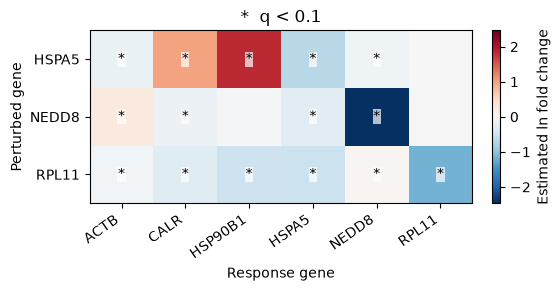

In [5]:
labels = obs.loc[~control, ["gene_transcript", "gene"]].drop_duplicates().set_index("gene_transcript")["gene"]
tested["target"] = tested["element"].map(labels)
assert tested["target"].notna().all()
effects = tested.pivot(index="target", columns="gene", values="posterior_mean")
q_values = tested.pivot(index="target", columns="gene", values=q)
limit = np.abs(effects.to_numpy()).max()
fig, ax = plt.subplots(figsize=(5.5, 2.8), layout="constrained")
image = ax.imshow(effects, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
for row, col in zip(*np.where(q_values.to_numpy() < 0.1)):
    ax.text(col, row, "*", ha="center", va="center", color="black",
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.7, "pad":0.4})
ax.set_xticks(range(len(effects.columns)), effects.columns, rotation=35, ha="right")
ax.set_yticks(range(len(effects.index)), effects.index)
ax.set(xlabel="Response gene", ylabel="Perturbed gene", title="*  q < 0.1")
fig.colorbar(image, ax=ax, label="Estimated ln fold change")
plt.show()

Read each row across to follow one perturbation. In the HSPA5 row, compare the HSPA5 column with CALR and HSP90B1. Color shows effect direction and size, while a star reports the multiple-testing decision. The non-targeting cells define the reference cohort and their construct labels have no test p-values in this run.